# Finite-size analysis — fixed peak-centered band

For each network size and seed, this notebook:
1. Loads and concatenates 4 consecutive simulation segments.
2. Loads LFP, excitatory population rate, and inhibitory population rate.
3. Computes
   \[
   r_{pop}(t)=0.8r_E(t)+0.2r_I(t)
   \]
4. Computes a Welch PSD separately for every realization.
5. Averages the PSDs across **all sizes and seeds** and detects one common oscillation frequency \(f_0\) inside a predefined search range.
6. Uses the **same fixed frequency window** \(f_0\pm\Delta f\) for every size and every realization.
7. Quantifies oscillation strength for each realization as
   \[
   A_{osc}=\sqrt{\int_{f_0-\Delta f}^{f_0+\Delta f}PSD(f)\,df}.
   \]
8. Averages these realization-level amplitudes only after the fixed-band integration.
9. Saves the finite-size summary and plots oscillation strength versus \(N\) and \(1/\sqrt{N}\).

The key point is that the peak is **not** detected separately in each trial or separately for each network size. This prevents weak/noisy spectra at large \(N\) from moving the integration window onto a random spectral fluctuation.


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat
from scipy.signal import welch


## Parameters

In [2]:
#Network linear sizes in micrometers
Size_list = np.array(
    [1000, 1250, 1500, 1750, 2000, 2250, 2500],
    dtype=float,
)

n_sizes = len(Size_list)

# Four 500-ms runs are saved for each network
n_iterations = 4
seed_list = np.arange(1, 6)
n_seeds = len(seed_list)
segment_duration_s = 0.5

# LFP StateMonitor sampling rate
fs_LFP = 1000.0  # Hz

# Frequency interval in which the common oscillatory peak is searched.
# Keep this wide enough to contain the oscillation, but narrow enough to
# exclude unrelated spectral peaks.
peak_search_band = (10.0, 100.0)  # Hz

# Half-width of the fixed integration band around the common peak.
# With a 1-s Welch window the frequency resolution is ~1 Hz, so +/- 3 Hz
# includes several bins around the peak. Increase this (e.g. to 5 Hz) only
# if the grand-average peak is visibly broader.
peak_half_width_hz = 5.0

# Welch window duration
welch_window_s = 1.0

# Folder containing the .mat files.
# Leave as "." if the notebook is in the same folder as the data.
DATA_DIR = Path(".")


FIT_START_INDEX = 0
N_BOOTSTRAP = 20_000
CONFIDENCE_LEVEL = 0.95
RNG_SEED = 20260924

input_drive = 1.4   
output_file = f"FiniteSize_peakcentered_nu{input_drive}_g3.16.mat"

def finite_size_fit_with_bootstrap_intercept_ci(x, y_mean, seed_values, *, rng):
    """Fit A_osc = a / sqrt(N) + b and return a bootstrap CI for b."""
    x = np.asarray(x, dtype=float)
    y_mean = np.asarray(y_mean, dtype=float)
    seed_values = np.asarray(seed_values, dtype=float)

    if seed_values.ndim != 2 or seed_values.shape[0] != x.size:
        raise ValueError("seed_values must have shape (n_sizes, n_seeds).")
    if y_mean.shape != x.shape:
        raise ValueError("x and y_mean must have the same shape.")

    coefficients = np.polyfit(x, y_mean, 1)
    bootstrap_means = np.empty((N_BOOTSTRAP, x.size), dtype=float)

    for i, values_at_size in enumerate(seed_values):
        values_at_size = values_at_size[np.isfinite(values_at_size)]
        if values_at_size.size < 2:
            raise ValueError("At least two valid seeds are required at every size.")
        draw_indices = rng.integers(
            0,
            values_at_size.size,
            size=(N_BOOTSTRAP, values_at_size.size),
        )
        bootstrap_means[:, i] = values_at_size[draw_indices].mean(axis=1)

    design = np.column_stack((x, np.ones_like(x)))
    bootstrap_coefficients = np.linalg.lstsq(
        design,
        bootstrap_means.T,
        rcond=None,
    )[0]
    bootstrap_intercepts = bootstrap_coefficients[1]

    alpha = 1.0 - CONFIDENCE_LEVEL
    intercept_ci = np.quantile(
        bootstrap_intercepts,
        [alpha / 2.0, 1.0 - alpha / 2.0],
    )
    return coefficients, intercept_ci


## Number of neurons

In [3]:
# MATLAB:
# Total_nr_neurons = 28000 * (Volume/mm^2)
# with Size_x = Size_y

N_total = 28000.0 * (Size_list / 1000.0) ** 2

N_total


array([ 28000.,  43750.,  63000.,  85750., 112000., 141750., 175000.])

## Storage arrays

In [4]:
# Sampling frequencies of the population-rate recordings
fs_rate_all = np.full((n_sizes, n_seeds), np.nan)

# PSD arrays are allocated after the first spectrum is computed, because
# their final frequency dimension depends on the Welch settings.
rate_psd = None
LFP_psd = None
f_rate = None
f_LFP = None


## First pass: compute and store every realization's PSD

No oscillation amplitude is measured yet. The purpose of this pass is only to obtain all PSDs on a common frequency grid.


In [5]:
for isize, Size_x in enumerate(Size_list):
    Jindex = isize

    for iseed, seed_id in enumerate(seed_list):
        rate_E_segments = []
        rate_I_segments = []
        LFP_segments = []

        samples_per_rate_segment = None

        for iteration in range(n_iterations):
            # -------------------------
            # Excitatory population rate
            # -------------------------
            filename_E = DATA_DIR / f"RATE_E_i{iteration}_J{Jindex}_{seed_id}.mat"
            tmp_E = loadmat(filename_E)
            current_E = np.asarray(tmp_E["data"], dtype=float).squeeze().reshape(-1)

            # -------------------------
            # Inhibitory population rate
            # -------------------------
            filename_I = DATA_DIR / f"RATE_I_i{iteration}_J{Jindex}_{seed_id}.mat"
            tmp_I = loadmat(filename_I)
            current_I = np.asarray(tmp_I["data"], dtype=float).squeeze().reshape(-1)

            if len(current_E) != len(current_I):
                raise ValueError(
                    "E and I rate files have different lengths "
                    f"for J{Jindex}, seed {seed_id}, iteration {iteration}."
                )

            if samples_per_rate_segment is None:
                samples_per_rate_segment = len(current_E)
            elif len(current_E) != samples_per_rate_segment:
                raise ValueError("Rate segments have inconsistent lengths.")

            # -------------------------
            # LFP
            # -------------------------
            filename_LFP = DATA_DIR / f"LFP_i{iteration}_J{Jindex}_{seed_id}.mat"
            tmp_LFP = loadmat(filename_LFP)
            current_LFP = np.asarray(tmp_LFP["data"], dtype=float)

            # MATLAB expects LFP as [time x channels].
            # If a single channel is stored as a vector, make it 2D.
            if current_LFP.ndim == 1:
                current_LFP = current_LFP[:, None]

            rate_E_segments.append(current_E)
            rate_I_segments.append(current_I)
            LFP_segments.append(current_LFP)

        # Concatenate the four consecutive segments
        rate_E = np.concatenate(rate_E_segments, axis=0)
        rate_I = np.concatenate(rate_I_segments, axis=0)
        LFP = np.concatenate(LFP_segments, axis=0)

        # -------------------------
        # Sampling frequency of rates
        # -------------------------
        fs_rate = samples_per_rate_segment / segment_duration_s
        fs_rate_all[isize, iseed] = fs_rate

        rate_pop = 0.8 * rate_E + 0.2 * rate_I

        # ============================================================
        # PSD: population rate
        # ============================================================
        rate_pop_zero_mean = rate_pop - np.mean(rate_pop)

        window_samples = int(round(welch_window_s * fs_rate))
        window_samples = min(window_samples, len(rate_pop_zero_mean))
        overlap_samples = window_samples // 2
        nfft = window_samples

        f_this, Pxx = welch(
            rate_pop_zero_mean,
            fs=fs_rate,
            window="hamming",
            nperseg=window_samples,
            noverlap=overlap_samples,
            nfft=nfft,
            detrend=False,
            scaling="density",
        )

        # Allocate on the first realization and require the same frequency
        # grid thereafter. This is important because the PSDs will be averaged.
        if rate_psd is None:
            f_rate = f_this.copy()
            rate_psd = np.full((n_sizes, n_seeds, len(f_rate)), np.nan)
        elif not np.allclose(f_this, f_rate):
            raise ValueError(
                "Population-rate Welch frequency grids differ between realizations. "
                "Use identical sampling rates and Welch settings before averaging PSDs."
            )

        rate_psd[isize, iseed, :] = Pxx

        # ============================================================
        # PSD: LFP
        # ============================================================
        # Demean each channel over the entire concatenated recording
        LFP_zero_mean = LFP - np.mean(LFP, axis=0, keepdims=True)

        window_samples_LFP = int(round(welch_window_s * fs_LFP))
        window_samples_LFP = min(window_samples_LFP, LFP_zero_mean.shape[0])
        overlap_samples_LFP = window_samples_LFP // 2
        nfft_LFP = window_samples_LFP

        f_LFP_this, Pxx_LFP = welch(
            LFP_zero_mean,
            fs=fs_LFP,
            window="hamming",
            nperseg=window_samples_LFP,
            noverlap=overlap_samples_LFP,
            nfft=nfft_LFP,
            detrend=False,
            scaling="density",
            axis=0,
        )

        # Average PSD across LFP channels within this realization
        Pxx_LFP_mean = np.mean(Pxx_LFP, axis=1)

        if LFP_psd is None:
            f_LFP = f_LFP_this.copy()
            LFP_psd = np.full((n_sizes, n_seeds, len(f_LFP)), np.nan)
        elif not np.allclose(f_LFP_this, f_LFP):
            raise ValueError(
                "LFP Welch frequency grids differ between realizations."
            )

        LFP_psd[isize, iseed, :] = Pxx_LFP_mean

print("Finished computing PSDs.")
print("rate_psd shape:", rate_psd.shape)
print("LFP_psd shape:", LFP_psd.shape)


Finished computing PSDs.
rate_psd shape: (7, 5, 5001)
LFP_psd shape: (7, 5, 501)


## Common oscillation frequency

The common peak is detected from the PSD averaged across all network sizes and seeds. The search is performed only inside `peak_search_band`.

Rates and LFP are treated separately because they are different observables, but within each observable the same peak frequency and the same integration band are used for every \(N\) and every seed.


In [6]:
# Grand-average PSDs across all sizes and seeds
grand_rate_psd = np.nanmean(rate_psd, axis=(0, 1))
grand_LFP_psd = np.nanmean(LFP_psd, axis=(0, 1))


def find_common_peak(frequency, grand_psd, search_band):
    search_idx = (
        (frequency >= search_band[0])
        & (frequency <= search_band[1])
    )

    if np.sum(search_idx) < 1:
        raise ValueError("No frequency bins inside peak_search_band.")

    f_search = frequency[search_idx]
    p_search = grand_psd[search_idx]

    return f_search[np.argmax(p_search)]


common_peak_freq_rate = find_common_peak(
    f_rate,
    grand_rate_psd,
    peak_search_band,
)

common_peak_freq_LFP = find_common_peak(
    f_LFP,
    grand_LFP_psd,
    peak_search_band,
)

rate_integration_band = (
    common_peak_freq_rate - peak_half_width_hz,
    common_peak_freq_rate + peak_half_width_hz,
)

LFP_integration_band = (
    common_peak_freq_LFP - peak_half_width_hz,
    common_peak_freq_LFP + peak_half_width_hz,
)

print(f"Common rate peak: {common_peak_freq_rate:.2f} Hz")
print(
    "Rate integration band: "
    f"{rate_integration_band[0]:.2f}–{rate_integration_band[1]:.2f} Hz"
)
print(f"Common LFP peak: {common_peak_freq_LFP:.2f} Hz")
print(
    "LFP integration band: "
    f"{LFP_integration_band[0]:.2f}–{LFP_integration_band[1]:.2f} Hz"
)


Common rate peak: 31.00 Hz
Rate integration band: 26.00–36.00 Hz
Common LFP peak: 31.00 Hz
LFP integration band: 26.00–36.00 Hz


## Diagnostic: grand-average spectra and fixed bands

Inspect this plot before interpreting the scaling. The shaded interval should contain the full oscillatory peak without becoming a broad-band measure.


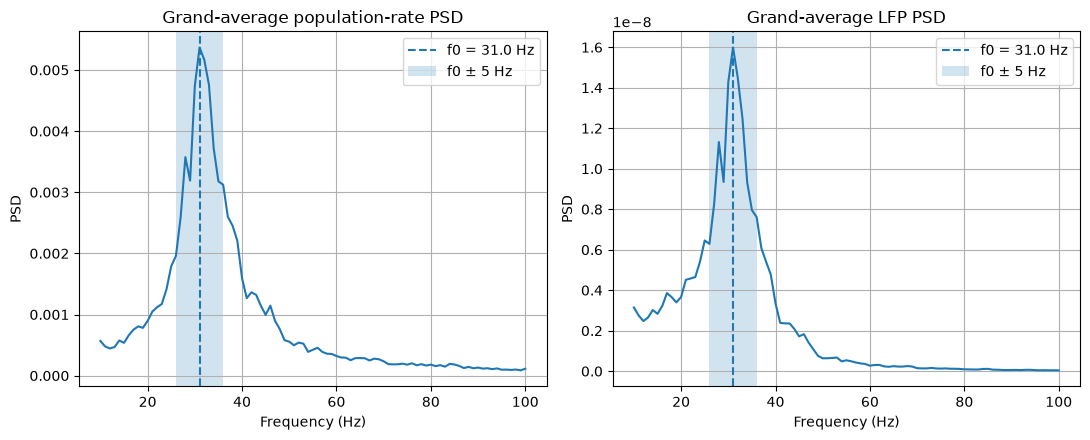

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Population rate
rate_plot_idx = (
    (f_rate >= peak_search_band[0])
    & (f_rate <= peak_search_band[1])
)
axes[0].plot(f_rate[rate_plot_idx], grand_rate_psd[rate_plot_idx])
axes[0].axvline(
    common_peak_freq_rate,
    linestyle="--",
    label=f"f0 = {common_peak_freq_rate:.1f} Hz",
)
axes[0].axvspan(
    rate_integration_band[0],
    rate_integration_band[1],
    alpha=0.2,
    label=f"f0 ± {peak_half_width_hz:g} Hz",
)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("PSD")
axes[0].set_title("Grand-average population-rate PSD")
axes[0].legend()
axes[0].grid(True)

# LFP
LFP_plot_idx = (
    (f_LFP >= peak_search_band[0])
    & (f_LFP <= peak_search_band[1])
)
axes[1].plot(f_LFP[LFP_plot_idx], grand_LFP_psd[LFP_plot_idx])
axes[1].axvline(
    common_peak_freq_LFP,
    linestyle="--",
    label=f"f0 = {common_peak_freq_LFP:.1f} Hz",
)
axes[1].axvspan(
    LFP_integration_band[0],
    LFP_integration_band[1],
    alpha=0.2,
    label=f"f0 ± {peak_half_width_hz:g} Hz",
)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("PSD")
axes[1].set_title("Grand-average LFP PSD")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


## Fixed-band oscillation amplitude for every realization

The peak frequency has now been fixed. Each realization is integrated over exactly the same frequency interval, and only then are means and error bars computed across seeds.


In [8]:
# Realization-level results
osc_power = np.full((n_sizes, n_seeds), np.nan)
osc_strength = np.full((n_sizes, n_seeds), np.nan)

LFP_osc_power = np.full((n_sizes, n_seeds), np.nan)
LFP_osc_strength = np.full((n_sizes, n_seeds), np.nan)

rate_band_idx = (
    (f_rate >= rate_integration_band[0])
    & (f_rate <= rate_integration_band[1])
)
LFP_band_idx = (
    (f_LFP >= LFP_integration_band[0])
    & (f_LFP <= LFP_integration_band[1])
)

if np.sum(rate_band_idx) < 2:
    raise ValueError("Not enough rate frequency bins inside the integration band.")
if np.sum(LFP_band_idx) < 2:
    raise ValueError("Not enough LFP frequency bins inside the integration band.")

for isize in range(n_sizes):
    for iseed in range(n_seeds):
        osc_power[isize, iseed] = np.trapezoid(
            rate_psd[isize, iseed, rate_band_idx],
            f_rate[rate_band_idx],
        )
        osc_strength[isize, iseed] = np.sqrt(osc_power[isize, iseed])

        LFP_osc_power[isize, iseed] = np.trapezoid(
            LFP_psd[isize, iseed, LFP_band_idx],
            f_LFP[LFP_band_idx],
        )
        LFP_osc_strength[isize, iseed] = np.sqrt(
            LFP_osc_power[isize, iseed]
        )


## Summary statistics


In [9]:
mean_osc_strength = np.nanmean(osc_strength, axis=1)
std_osc_strength = np.nanstd(osc_strength, axis=1, ddof=1)
n_valid = np.sum(~np.isnan(osc_strength), axis=1)
sem_osc_strength = std_osc_strength / np.sqrt(n_valid)
mean_osc_power = np.nanmean(osc_power, axis=1)

LFP_mean_osc_strength = np.nanmean(LFP_osc_strength, axis=1)
LFP_std_osc_strength = np.nanstd(LFP_osc_strength, axis=1, ddof=1)
LFP_n_valid = np.sum(~np.isnan(LFP_osc_strength), axis=1)
LFP_sem_osc_strength = LFP_std_osc_strength / np.sqrt(LFP_n_valid)
LFP_mean_osc_power = np.nanmean(LFP_osc_power, axis=1)


## Save results


In [10]:


savemat(
    output_file,
    {
        "N_total": N_total,

        # Realization-level fixed-band results
        "osc_strength": osc_strength,
        "osc_power": osc_power,
        "LFP_osc_strength": LFP_osc_strength,
        "LFP_osc_power": LFP_osc_power,

        # Common peak and fixed band used for every realization
        "common_peak_freq_rate": common_peak_freq_rate,
        "common_peak_freq_LFP": common_peak_freq_LFP,
        "peak_half_width_hz": peak_half_width_hz,
        "rate_integration_band": np.asarray(rate_integration_band),
        "LFP_integration_band": np.asarray(LFP_integration_band),
        "peak_search_band": np.asarray(peak_search_band),

        # Summary quantities
        "mean_osc_strength": mean_osc_strength,
        "std_osc_strength": std_osc_strength,
        "sem_osc_strength": sem_osc_strength,
        "mean_osc_power": mean_osc_power,
        "LFP_mean_osc_strength": LFP_mean_osc_strength,
        "LFP_std_osc_strength": LFP_std_osc_strength,
        "LFP_sem_osc_strength": LFP_sem_osc_strength,
        "LFP_mean_osc_power": LFP_mean_osc_power,

        # PSDs retained so that the choice of band can be inspected/reanalyzed
        "f_rate": f_rate,
        "grand_rate_psd": grand_rate_psd,
        "f_LFP": f_LFP,
        "grand_LFP_psd": grand_LFP_psd,
    },
)

print(f"Saved {output_file}")
print("osc_strength shape:", osc_strength.shape)


Saved FiniteSize_peakcentered_nu1.6_g3.18.mat
osc_strength shape: (7, 5)


## Finite-size summary: rates


Rate fit intercept b = -0.0003061 Hz; 95% bootstrap CI = [-0.02622, 0.026] Hz


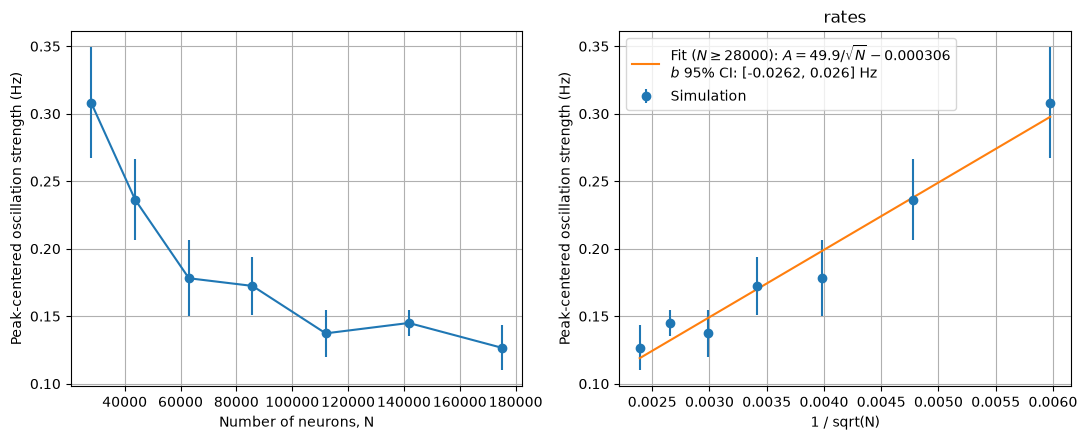

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Oscillation strength vs N
axes[0].errorbar(
    N_total,
    mean_osc_strength,
    yerr=std_osc_strength,
    fmt="o-",
)
axes[0].set_xlabel("Number of neurons, N")
axes[0].set_ylabel("Peak-centered oscillation strength (Hz)")
axes[0].grid(True)

# Oscillation strength vs 1/sqrt(N)
x_finite = 1.0 / np.sqrt(N_total)

idx = np.argsort(x_finite)
x_sorted = x_finite[idx]
y_sorted = mean_osc_strength[idx]
yerr_sorted = std_osc_strength[idx]

axes[1].errorbar(
    x_sorted,
    y_sorted,
    yerr=yerr_sorted,
    fmt="o",
    label="Simulation",
)

# Fit only the asymptotic, large-system regime.
fit_slice = slice(FIT_START_INDEX, None)
x_fit_data = x_finite[fit_slice]
mean_fit_data = mean_osc_strength[fit_slice]
seed_fit_data = osc_strength[fit_slice, :]

p_rate, rate_intercept_ci = finite_size_fit_with_bootstrap_intercept_ci(
    x_fit_data,
    mean_fit_data,
    seed_fit_data,
    rng=np.random.default_rng(RNG_SEED),
)
confidence_pct = int(100 * CONFIDENCE_LEVEL)
print(
    f"Rate fit intercept b = {p_rate[1]:.4g} Hz; {confidence_pct}% bootstrap CI "
    f"= [{rate_intercept_ci[0]:.4g}, {rate_intercept_ci[1]:.4g}] Hz"
)

x_fit = np.linspace(np.min(x_fit_data), np.max(x_fit_data), 100)
y_fit = np.polyval(p_rate, x_fit)

axes[1].plot(
    x_fit,
    y_fit,
    "-",
    label=(
        rf"Fit ($N \geq {N_total[FIT_START_INDEX]:.0f}$): "
        rf"$A={p_rate[0]:.3g}/\sqrt{{N}}{p_rate[1]:+.3g}$"
        "\n"
        rf"$b$ {confidence_pct}% CI: "
        rf"[{rate_intercept_ci[0]:.3g}, {rate_intercept_ci[1]:.3g}] Hz"
    ),
)

axes[1].set_xlabel("1 / sqrt(N)")
axes[1].set_ylabel("Peak-centered oscillation strength (Hz)")
axes[1].grid(True)
axes[1].legend()
axes[1].set_title("rates")

plt.tight_layout()
plt.show()


## Finite-size summary: LFP


LFP fit intercept b = -0.000119; 95% bootstrap CI = [-0.0001677, -6.988e-05]


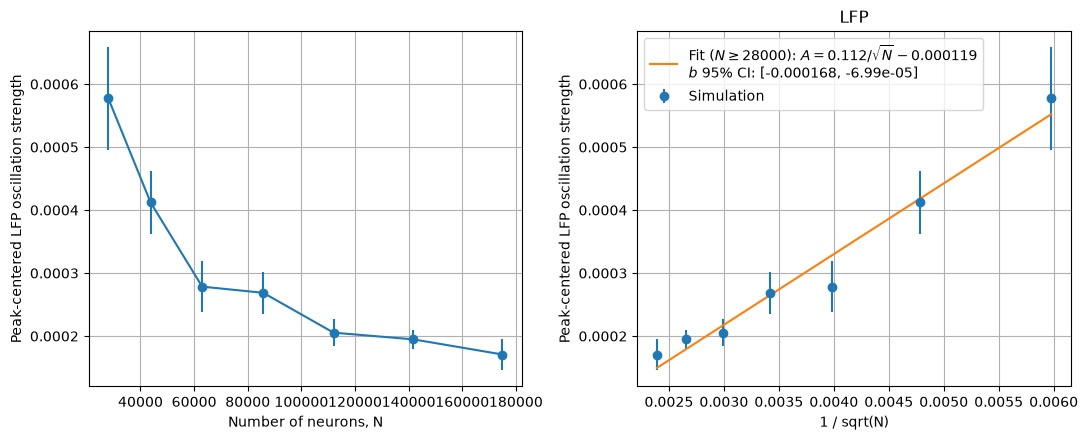

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Oscillation strength vs N
axes[0].errorbar(
    N_total,
    LFP_mean_osc_strength,
    yerr=LFP_std_osc_strength,
    fmt="o-",
)
axes[0].set_xlabel("Number of neurons, N")
axes[0].set_ylabel("Peak-centered LFP oscillation strength")
axes[0].grid(True)

# Oscillation strength vs 1/sqrt(N)
x_finite = 1.0 / np.sqrt(N_total)

idx = np.argsort(x_finite)
x_sorted = x_finite[idx]
y_sorted = LFP_mean_osc_strength[idx]
yerr_sorted = LFP_std_osc_strength[idx]

axes[1].errorbar(
    x_sorted,
    y_sorted,
    yerr=yerr_sorted,
    fmt="o",
    label="Simulation",
)

# Fit only the asymptotic, large-system regime.
fit_slice = slice(FIT_START_INDEX, None)
x_fit_data = x_finite[fit_slice]
mean_fit_data = LFP_mean_osc_strength[fit_slice]
seed_fit_data = LFP_osc_strength[fit_slice, :]

p_LFP, LFP_intercept_ci = finite_size_fit_with_bootstrap_intercept_ci(
    x_fit_data,
    mean_fit_data,
    seed_fit_data,
    rng=np.random.default_rng(RNG_SEED + 1),
)
confidence_pct = int(100 * CONFIDENCE_LEVEL)
print(
    f"LFP fit intercept b = {p_LFP[1]:.4g}; {confidence_pct}% bootstrap CI "
    f"= [{LFP_intercept_ci[0]:.4g}, {LFP_intercept_ci[1]:.4g}]"
)

x_fit = np.linspace(np.min(x_fit_data), np.max(x_fit_data), 100)
y_fit = np.polyval(p_LFP, x_fit)

axes[1].plot(
    x_fit,
    y_fit,
    "-",
    label=(
        rf"Fit ($N \geq {N_total[FIT_START_INDEX]:.0f}$): "
        rf"$A={p_LFP[0]:.3g}/\sqrt{{N}}{p_LFP[1]:+.3g}$"
        "\n"
        rf"$b$ {confidence_pct}% CI: "
        rf"[{LFP_intercept_ci[0]:.3g}, {LFP_intercept_ci[1]:.3g}]"
    ),
)

axes[1].set_xlabel("1 / sqrt(N)")
axes[1].set_ylabel("Peak-centered LFP oscillation strength")
axes[1].grid(True)
axes[1].legend()
axes[1].set_title("LFP")

plt.tight_layout()
plt.show()
